# Week 2 – Task 2: Exploratory Data Analysis (EDA)

**Dataset:** Global Superstore  
**Goal:** Understand the data, find patterns, create visualizations, and generate business insights.

### What we will do
1. Load the data
2. Check rows, columns, missing values and duplicates
3. Calculate basic statistics
4. Create different charts
5. Analyze category, region, segment and products
6. Check monthly sales trend
7. Check correlation and Sales vs Profit
8. Write insights and recommendations


## 1. Import Libraries

We use:
- **Pandas** → data analysis
- **NumPy** → numerical calculations
- **Matplotlib & Seaborn** → charts


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")


Libraries imported successfully


## 2. Load the Dataset

Make sure `global_superstore_cleaned.csv` is in the same folder as this notebook.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving global_superstore_cleaned.csv to global_superstore_cleaned.csv


In [4]:
import pandas as pd

file_path = "global_superstore_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 51290
Columns: 24


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,581.495063,7.0,0.0,92.025,57.21,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",581.495063,9.0,0.1,-55.215,57.21,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",581.495063,9.0,0.1,92.025,57.21,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",581.495063,5.0,0.1,-55.215,57.21,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",581.495063,8.0,0.0,92.025,57.21,Critical


## 3. Understand the Dataset

First, check the column names and data types.


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'city', 'state', 'country', 'postal_code', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority']

Data types:
row_id              int64
order_id           object
order_date         object
ship_date          object
ship_mode          object
customer_id        object
customer_name      object
segment            object
city               object
state              object
country            object
postal_code        object
market             object
region             object
product_id         object
category           object
sub_category       object
product_name       object
sales             float64
quantity          float64
discount          float64
profit            float64
shipping_cost     float64
order_priority     object
dtype: object


## 4. Check Missing Values and Duplicates

This helps us understand data quality.


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
row_id            0
order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_id       0
customer_name     0
segment           0
city              0
state             0
country           0
postal_code       0
market            0
region            0
product_id        0
category          0
sub_category      0
product_name      0
sales             0
quantity          0
discount          0
profit            0
shipping_cost     0
order_priority    0
dtype: int64

Duplicate rows: 0


## 5. Descriptive Statistics

`describe()` gives useful statistics such as:
- Mean
- Standard deviation
- Minimum
- Maximum
- Quartiles


In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns].describe().T


,count,mean,std,min,25%,50%,75%,max
row_id,51290.0,25645.500000,14806.291990,1.000,12823.250000,25645.500,38467.7500,51290.000000
sales,51290.0,172.359178,190.096672,0.444,30.758625,85.053,251.0532,581.495063
quantity,51290.0,3.438731,2.147765,1.000,2.000000,3.000,5.0000,9.500000
discount,51290.0,0.130049,0.182638,0.000,0.000000,0.000,0.2000,0.500000
profit,51290.0,18.092440,39.851666,-55.215,0.000000,9.240,36.8100,92.025000
shipping_cost,51290.0,16.711757,18.976293,0.002,2.610000,7.790,24.4500,57.210000


## 6. Sales Distribution – Histogram

A histogram shows how Sales values are distributed.


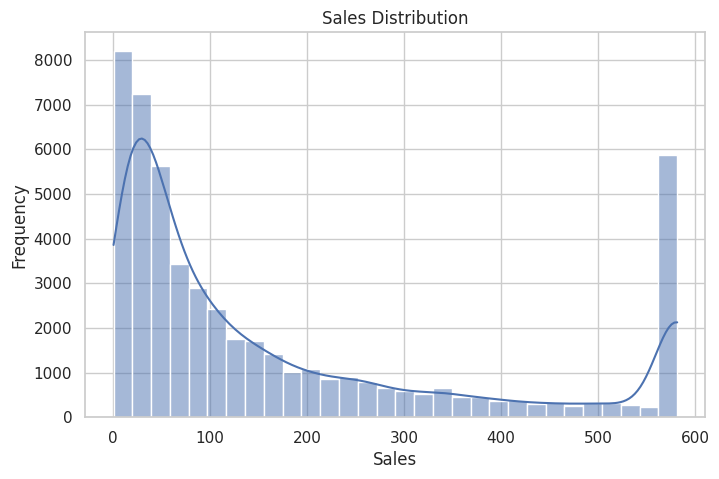

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["sales"], bins=30, kde=True)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


## 7. Profit Distribution – KDE Plot

A KDE plot shows the shape of the Profit distribution.


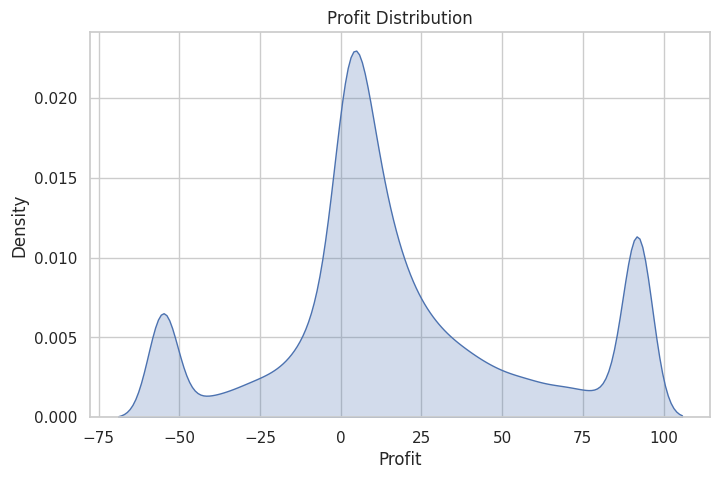

In [9]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="profit", fill=True)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Density")
plt.show()


## 8. Sales by Category – Box Plot

A box plot helps identify the spread of Sales and possible outliers for each category.


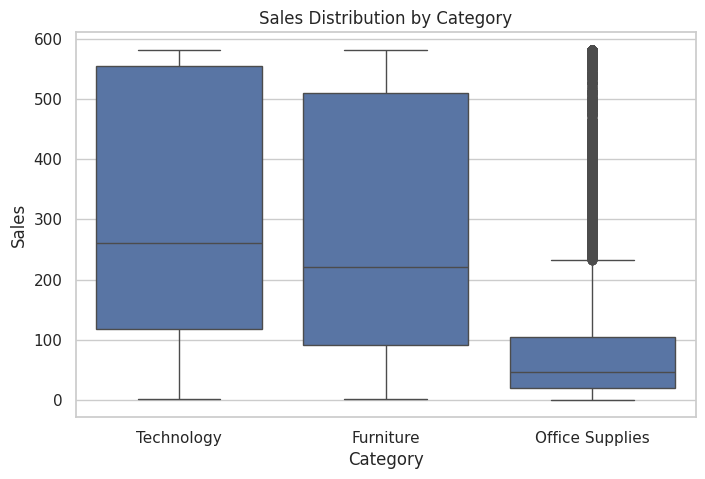

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="category", y="sales")

plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()


## 9. Total Sales by Category

We use `groupby()` to calculate total sales for each category.


category
Technology         3.078022e+06
Office Supplies    3.007390e+06
Furniture          2.754890e+06
Name: sales, dtype: float64


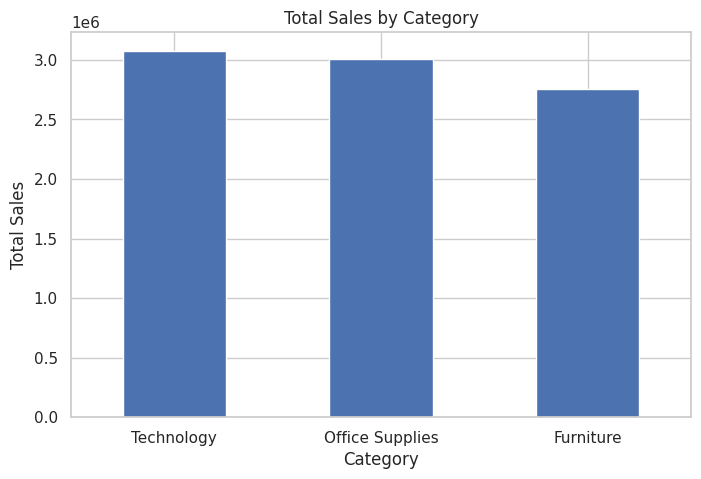

In [11]:
category_sales = df.groupby("category")["sales"].sum().sort_values(ascending=False)

print(category_sales)

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()


## 10. Total Profit by Category

This shows which categories generate the most profit.


category
Office Supplies    392508.1007
Technology         322332.2067
Furniture          213120.9636
Name: profit, dtype: float64


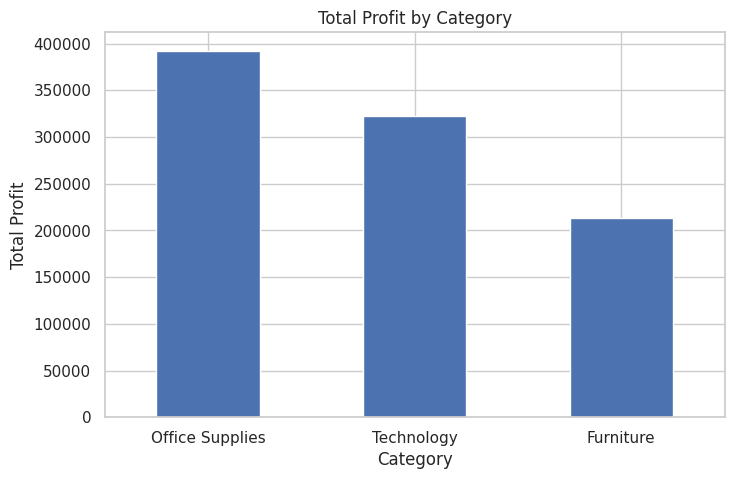

In [12]:
category_profit = df.groupby("category")["profit"].sum().sort_values(ascending=False)

print(category_profit)

category_profit.plot(kind="bar", figsize=(8, 5))
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()


## 11. Sales by Region

This helps us compare regional performance.


In [ ]:
region_sales = df.groupby("region")["sales"].sum().sort_values(ascending=False)

print(region_sales)

region_sales.plot(kind="bar", figsize=(9, 5))
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()


## 12. Monthly Sales Trend

We convert `order_date` into a date format and calculate monthly sales.


order_date
2011-01     71215.696245
2011-02     65294.225955
2011-03     90132.970650
2011-04     89170.516925
2011-05    103953.155920
2011-06    156868.438248
2011-07     83086.151313
2011-08    146640.832102
2011-09    182970.336697
2011-10    139920.175577
2011-11    200035.054210
2011-12    227046.047650
2012-01     94844.746613
2012-02     70425.732287
2012-03    113335.891500
2012-04    115219.513245
2012-05    146754.144453
2012-06    190487.312528
2012-07    110365.689257
2012-08    199202.786530
2012-09    204566.213703
2012-10    174745.596670
2012-11    243582.697142
2012-12    231995.810355
2013-01    124822.067255
2013-02    108621.396255
2013-03    136379.361528
2013-04    130202.546270
2013-05    177652.028455
2013-06    265608.012665
2013-07    167042.241000
2013-08    239910.562292
2013-09    278986.035365
2013-10    191846.344635
2013-11    267438.537840
2013-12    284565.101680
2014-01    159574.136735
2014-02    136628.059820
2014-03    181685.270538
2014-04    172

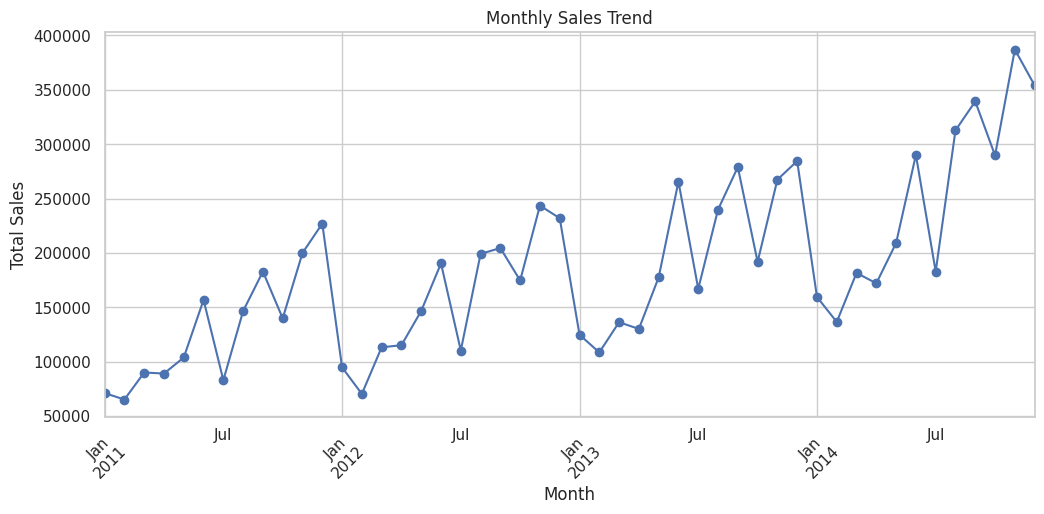

In [13]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

monthly_sales = df.groupby(
    df["order_date"].dt.to_period("M")
)["sales"].sum()

print(monthly_sales)

monthly_sales.plot(kind="line", figsize=(12, 5), marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()


## 13. Correlation Matrix

Correlation shows how numeric columns are related.

- Close to **+1** → strong positive relationship
- Close to **-1** → strong negative relationship
- Close to **0** → weak relationship


,row_id,sales,quantity,discount,profit,shipping_cost
row_id,1.000000,-0.093579,-0.184755,0.039008,-0.045880,-0.086611
sales,-0.093579,1.000000,0.357746,-0.110905,0.483261,0.890314
quantity,-0.184755,0.357746,1.000000,-0.006920,0.181680,0.329104
discount,0.039008,-0.110905,-0.006920,1.000000,-0.575859,-0.105130
profit,-0.045880,0.483261,0.181680,-0.575859,1.000000,0.441508
shipping_cost,-0.086611,0.890314,0.329104,-0.105130,0.441508,1.000000


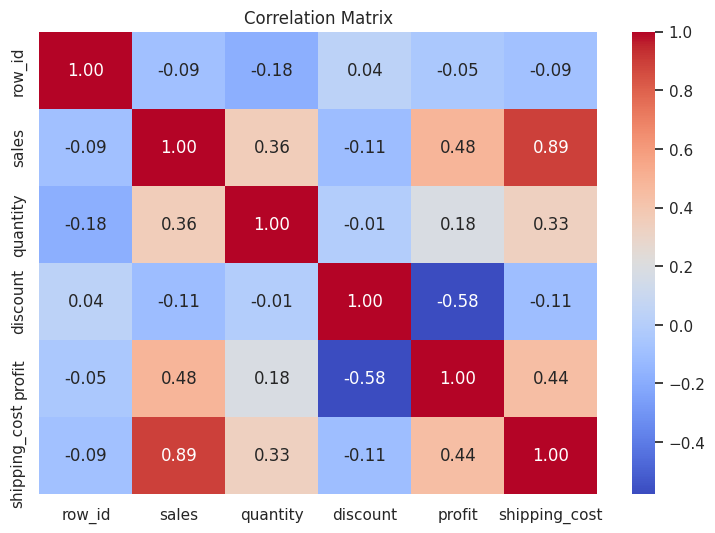

In [14]:
correlation = df[numeric_columns].corr()

display(correlation)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()


## 14. Sales vs Profit – Scatter Plot

This chart helps us understand the relationship between Sales and Profit.


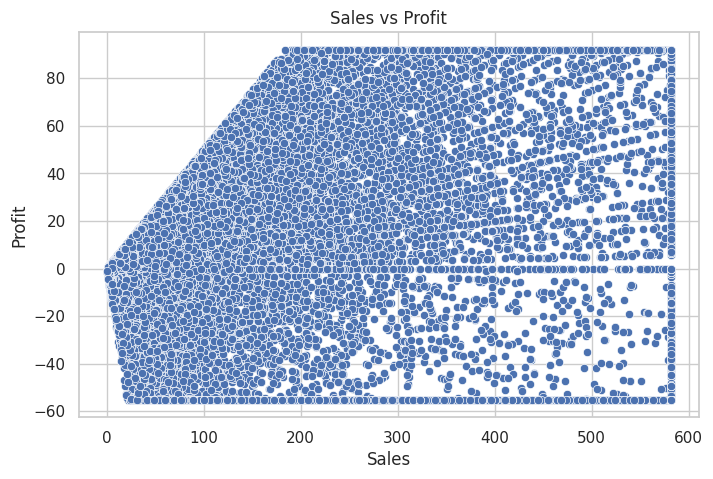

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="sales", y="profit")

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()


## 15. Sales by Customer Segment

This shows which customer segment contributes the most sales.


segment
Consumer       4.560979e+06
Corporate      2.675716e+06
Home Office    1.603607e+06
Name: sales, dtype: float64


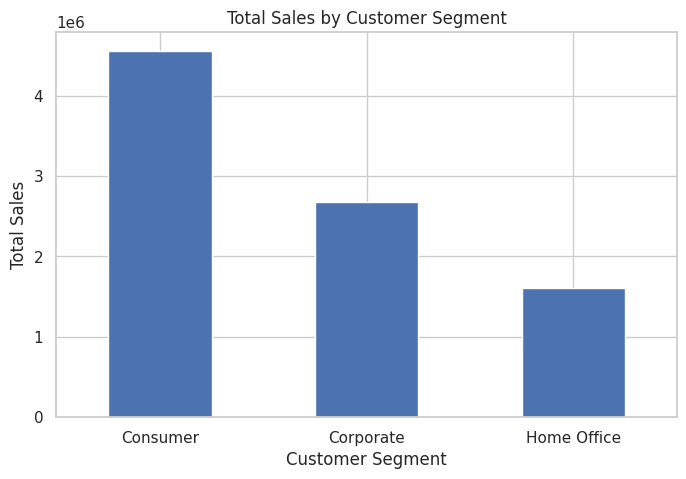

In [16]:
segment_sales = df.groupby("segment")["sales"].sum().sort_values(ascending=False)

print(segment_sales)

segment_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()


## 16. Top 10 Countries by Sales

We sort countries by sales and select the top 10.


In [ ]:
top_countries = (
    df.groupby("country")["sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_countries)

top_countries.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries by Sales")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()


## 17. Top 10 Products by Sales

This helps identify the best-selling products.


product_name
Eldon File Cart, Single Width                               30806.522763
Apple Smart Phone, Full Size                                28205.643813
Hon Executive Leather Armchair, Adjustable                  26279.513250
Nokia Smart Phone, Full Size                                26024.047688
Office Star Executive Leather Armchair, Adjustable          25171.017313
Rogers File Cart, Single Width                              23823.700175
Smead File Cart, Single Width                               22135.471425
Cisco Smart Phone, Full Size                                21651.383250
Harbour Creations Executive Leather Armchair, Adjustable    20855.768875
Tenex File Cart, Single Width                               20650.685175
Name: sales, dtype: float64


/tmp/ipykernel_8300/973695262.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


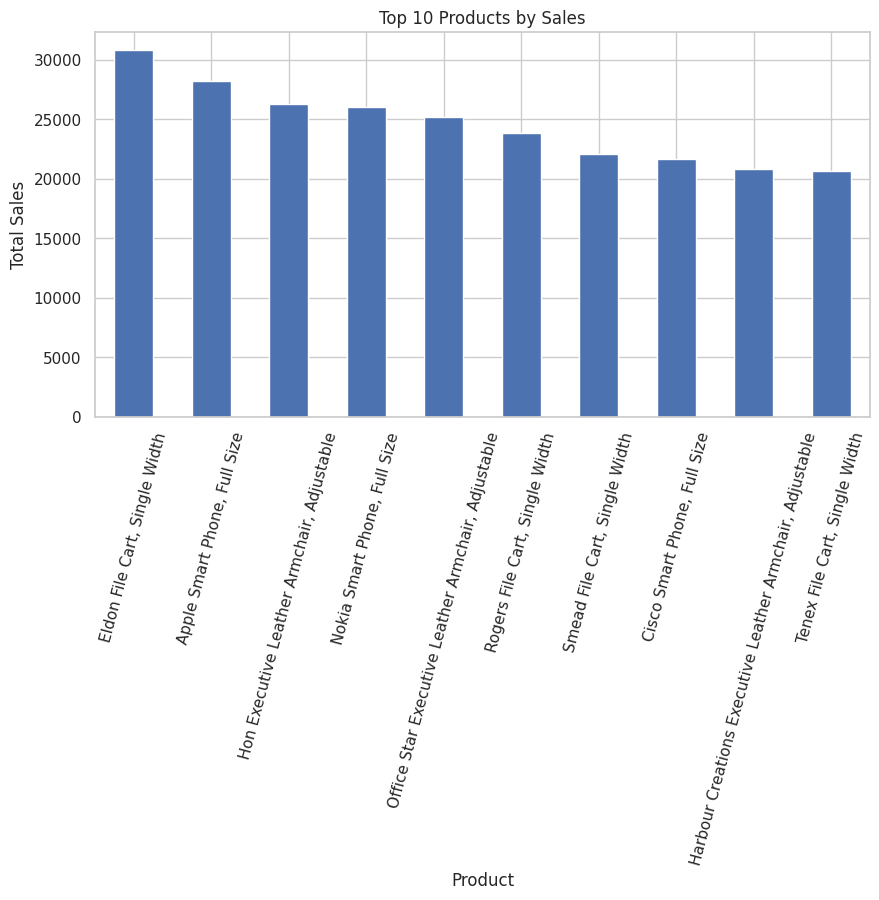

In [17]:
top_products = (
    df.groupby("product_name")["sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_products)

top_products.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


## 18. Profit Margin by Category

Profit Margin tells us how much profit is earned from sales.

**Formula:**  
Profit Margin % = Profit / Sales × 100


In [18]:
category_performance = df.groupby("category").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum")
)

category_performance["profit_margin_%"] = (
    category_performance["total_profit"] /
    category_performance["total_sales"] * 100
).round(2)

category_performance.sort_values("total_sales", ascending=False)


,total_sales,total_profit,profit_margin_%
category,,,
Technology,3.078022e+06,322332.2067,10.47
Office Supplies,3.007390e+06,392508.1007,13.05
Furniture,2.754890e+06,213120.9636,7.74


## 19. Key Insights

The code below automatically identifies the top category, region and customer segment.


In [20]:
# Create all required summaries for insights

category_sales = df.groupby("category")["sales"].sum().sort_values(ascending=False)

region_sales = df.groupby("region")["sales"].sum().sort_values(ascending=False)

segment_sales = df.groupby("segment")["sales"].sum().sort_values(ascending=False)

top_countries = (
    df.groupby("country")["sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products = (
    df.groupby("product_name")["sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("All summaries created successfully!")

All summaries created successfully!


In [21]:
best_category = category_sales.idxmax()
best_region = region_sales.idxmax()
best_segment = segment_sales.idxmax()
best_country = top_countries.idxmax()
best_product = top_products.idxmax()

print("Insight 1:", best_category, "has the highest total sales among categories.")
print("Insight 2:", best_region, "has the highest total sales among regions.")
print("Insight 3:", best_segment, "is the highest-sales customer segment.")
print("Insight 4:", best_country, "is the highest-sales country among the top 10.")
print("Insight 5:", best_product, "is the top product by sales.")

Insight 1: Technology has the highest total sales among categories.
Insight 2: Central has the highest total sales among regions.
Insight 3: Consumer is the highest-sales customer segment.
Insight 4: United States is the highest-sales country among the top 10.
Insight 5: Eldon File Cart, Single Width is the top product by sales.


## 20. Business Recommendations

Based on the analysis:

1. Focus marketing on high-performing categories and regions.
2. Monitor categories with high sales but low profit margins.
3. Use monthly sales trends for inventory and sales planning.
4. Create targeted strategies for the strongest customer segments.
5. Monitor top products and maintain sufficient stock.
6. Investigate low-profit or negative-profit products before increasing promotions.


## 21. Conclusion

EDA was performed on the Global Superstore dataset.

We analyzed:
- Dataset structure and data quality
- Descriptive statistics
- Sales and profit distributions
- Category performance
- Regional performance
- Monthly sales trends
- Customer segments
- Top countries and products
- Correlation
- Sales vs Profit
- Profit margins

These findings can help businesses improve sales planning, inventory decisions, marketing and profitability.


## 22. Task 2 Checklist

| Requirement | Status |
|---|---|
| Descriptive statistics | ✅ |
| Histogram | ✅ |
| KDE plot | ✅ |
| Box plot | ✅ |
| Bar charts | ✅ |
| Line chart / time trend | ✅ |
| Group-by analysis | ✅ |
| Correlation matrix | ✅ |
| Scatter plot | ✅ |
| 3+ insights | ✅ |
| Business recommendations | ✅ |
| Conclusion | ✅ |

**Task 2 EDA – Completed**
